# Submission 1: Dataset, EDA and Related Work
**Dataset:** A Benchmark Image Dataset for Scabies Detection (Scabies vs Healthy skin)

## A. Dataset information

| Item | Details |
|---|---|
| Name | A Benchmark Image Dataset for Scabies Detection_2.0 |
| Source | Mendeley Data: https://data.mendeley.com/datasets/mg6sb9b8x4/1 (DOI 10.17632/mg6sb9b8x4.1) |
| Authors / institution | Mrithunjoy Das Shiblu, Md Faisal Bin Abdul Aziz, Tanjim Mahmud, Piklu Datta, Nabonita Paul Hridi, Fatema Zahra (Comilla University) |
| Licence | CC BY 4.0 |
| Year | 2026 (published 27 April 2026) |
| Task type | Binary image classification |
| Classes | 2 (Scabies, Healthy) |
| Folders | Original and Augmented. This notebook uses the **Original** folder only |
| Collection | Smartphone photos, natural and indoor light, affected skin area only, no faces |
| Image size, channels, format | Computed in the cells below |

**Why the dataset matters:** Scabies is a contagious skin disease caused by a mite. It is common where people live close together and where there are few skin specialists. A model that can screen a smartphone photo could help find cases early, so treatment can start sooner and the disease spreads less.

In [1]:
import os
import glob
import hashlib
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps

%config InlineBackend.figure_format = 'jpeg'
plt.rcParams["figure.dpi"] = 90

BASE = "/Users/macbook/Desktop/projects/A Benchmark Image Dataset for Scabies Detection_2."
IMAGE_FOLDER = os.path.join(BASE, "SCAB_original")
CSV_FILE = os.path.join(BASE, "SCAB_metadata_CSV.csv")

In [2]:
meta = pd.read_csv(CSV_FILE)
meta = meta[meta["Image_id"].notna()].copy()
meta["Image_id"] = meta["Image_id"].astype(str).str.strip()
meta["label"] = meta["Class Label"].str.strip()
meta["patient"] = meta["Image_id"].str.extract(r"^(.+?)_IMG")[0]
meta["patient"] = meta["patient"].fillna(meta["Image_id"])

files = {}
for path in glob.glob(os.path.join(IMAGE_FOLDER, "**", "*"), recursive=True):
    if path.lower().endswith((".jpg", ".jpeg", ".png")):
        files[os.path.basename(path).lower()] = path

meta["path"] = meta["Image_id"].str.lower().map(files)
data = meta[meta["path"].notna()].reset_index(drop=True)

print("Rows in CSV:", len(meta))
print("Images found:", len(data))

Rows in CSV: 606
Images found: 606


In [3]:
sizes = []
for path in data["path"]:
    with Image.open(path) as im:
        sizes.append({"width": im.width, "height": im.height,
                      "channels": len(im.getbands()), "format": im.format})

data = pd.concat([data, pd.DataFrame(sizes)], axis=1)

print("Total images:", len(data))
print("Number of classes:", data["label"].nunique())
print("File format:", data["format"].unique().tolist())
print("Channels:", data["channels"].unique().tolist())
print()

summary = data.groupby("label").agg(images=("Image_id", "count"), patients=("patient", "nunique"))
summary["percent"] = (summary["images"] / summary["images"].sum() * 100).round(1)
display(summary)

print("Most common image sizes (width x height):")
display(data.groupby(["width", "height"]).size().sort_values(ascending=False).head(5).rename("images").to_frame())
print("Smallest side:", data[["width", "height"]].min().min(), "px | Largest side:", data[["width", "height"]].max().max(), "px")

Total images: 606
Number of classes: 2
File format: ['JPEG']
Channels: [3]



,images,patients,percent
label,,,
Healthy,200,55,33.0
Scabies,406,114,67.0


Most common image sizes (width x height):


images
width height        
512   512         12
      709          3
      596          3
      593          3
      517          3

Smallest side: 512 px | Largest side: 3349 px


## B. Exploratory data analysis (EDA)

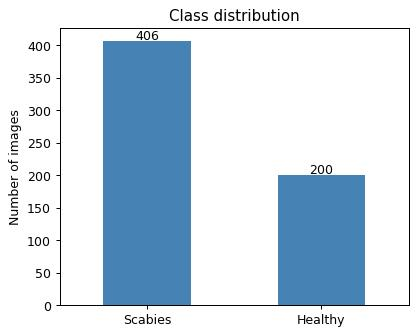

Imbalance ratio (largest class / smallest class): 2.03
The data is imbalanced.


In [4]:
counts = data["label"].value_counts()

ax = counts.plot(kind="bar", color="steelblue", figsize=(5, 4))
for i, v in enumerate(counts):
    ax.text(i, v + 3, str(v), ha="center")
ax.set_title("Class distribution")
ax.set_xlabel("")
ax.set_ylabel("Number of images")
plt.xticks(rotation=0)
plt.show()

ratio = counts.max() / counts.min()
print(f"Imbalance ratio (largest class / smallest class): {ratio:.2f}")
print("The data is imbalanced." if ratio >= 1.5 else "The data is roughly balanced.")

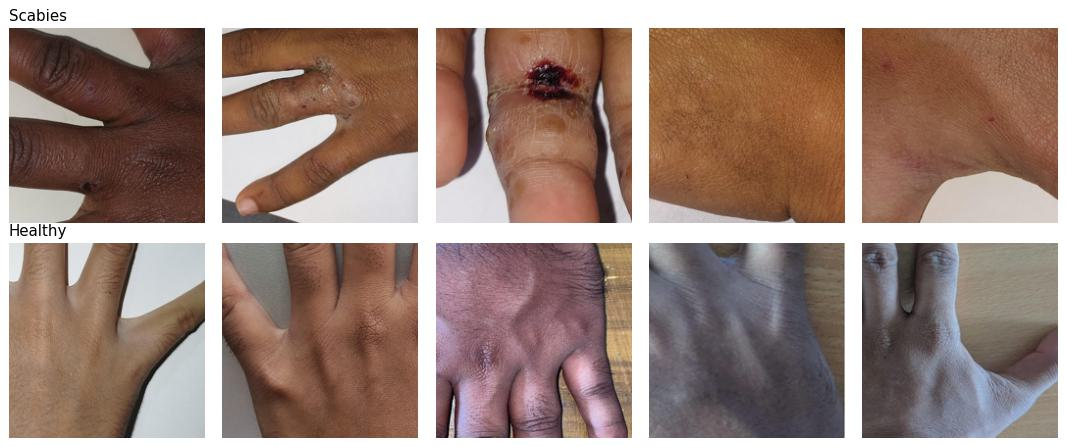

In [5]:
classes = counts.index.tolist()
fig, axes = plt.subplots(len(classes), 5, figsize=(12, 2.5 * len(classes)))

for row, name in enumerate(classes):
    picks = data[data["label"] == name].sample(5, random_state=42)["path"]
    for col, path in enumerate(picks):
        img = ImageOps.fit(Image.open(path).convert("RGB"), (200, 200))
        axes[row, col].imshow(img)
        axes[row, col].axis("off")
    axes[row, 0].set_title(name, loc="left", fontsize=12)

plt.tight_layout()
plt.show()

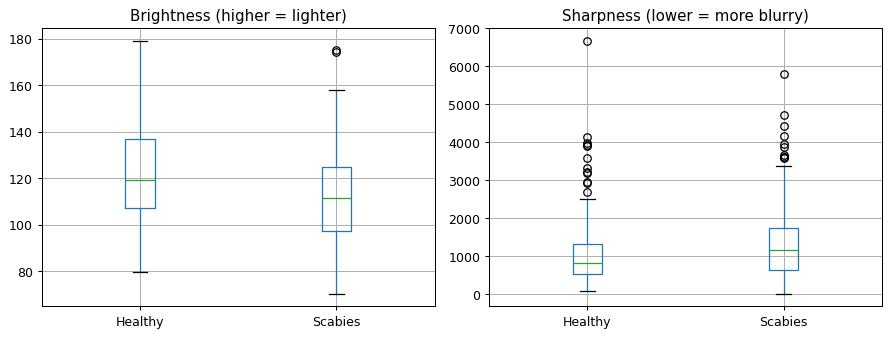

,brightness,sharpness
label,,
Healthy,121.4,1092.5
Scabies,112.0,1282.8


In [6]:
brightness, sharpness = [], []
for path in data["path"]:
    gray = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    gray = cv2.resize(gray, (256, 256))
    brightness.append(gray.mean())
    sharpness.append(cv2.Laplacian(gray, cv2.CV_64F).var())

data["brightness"] = brightness
data["sharpness"] = sharpness

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
data.boxplot(column="brightness", by="label", ax=axes[0])
data.boxplot(column="sharpness", by="label", ax=axes[1])
axes[0].set_title("Brightness (higher = lighter)")
axes[1].set_title("Sharpness (lower = more blurry)")
for ax in axes:
    ax.set_xlabel("")
plt.suptitle("")
plt.tight_layout()
plt.show()

display(data.groupby("label")[["brightness", "sharpness"]].mean().round(1))

In [7]:
data["md5"] = [hashlib.md5(Path(p).read_bytes()).hexdigest() for p in data["path"]]
duplicates = data.duplicated("md5", keep=False).sum()
not_square = (data["width"] != data["height"]).mean() * 100
different_sizes = data.groupby(["width", "height"]).ngroups

print("Summary of what the data shows")
print(f"- Imbalance: {counts.idxmax()} has {counts.max()} images and {counts.idxmin()} has {counts.min()} (ratio {ratio:.2f})")
print(f"- Image sizes: {different_sizes} different sizes, {not_square:.0f}% of images are not square")
print(f"- Exact duplicate files: {duplicates}")
print(f"- Brightness range: {data['brightness'].min():.0f} to {data['brightness'].max():.0f}")
print(f"- Sharpness range: {data['sharpness'].min():.0f} to {data['sharpness'].max():.0f}")

Summary of what the data shows
- Imbalance: Scabies has 406 images and Healthy has 200 (ratio 2.03)
- Image sizes: 577 different sizes, 98% of images are not square
- Exact duplicate files: 0
- Brightness range: 70 to 179
- Sharpness range: 14 to 6674


### Findings and the preprocessing plan

| Finding | What we will do |
|---|---|
| **Imbalance:** Scabies has about twice as many images as Healthy (see bar chart and ratio above). | Split with stratification so each split keeps the same class ratio. Use class weights in the loss. Report precision, recall and F1, not only accuracy. |
| **Image size:** Images are different sizes and not all are square (see size table above). | Centre-crop to a square, then resize to 224 x 224 so images are not stretched. |
| **Noise and quality:** These are smartphone photos taken in natural and indoor light, so brightness and sharpness change from image to image (see box plots). | Normalise pixel values. Add brightness and contrast changes during training so the model does not depend on lighting. |
| **Class similarity:** Scabies skin and healthy skin can look alike, and a model can learn background or lighting instead of the lesion (check the sample grid). | Use augmentation to make the model less sensitive to background. Check what the model looks at with Grad-CAM later. |
| **Duplicates and patients:** Several images can come from the same patient, and the dataset also has an Augmented folder made from the Original images. | Use the Original folder only. Keep all images of one patient in the same split. Augment the training set only, after splitting. |

**Augmentation planned for training images only:** horizontal and vertical flip, rotation up to 20 degrees, zoom, brightness and contrast change.

## C. Related work summary
There are few papers on scabies images. The table has scabies image papers and one wider paper on smartphone skin photos.

| # | Paper (author, year) | Dataset used | Model(s) | Approach (preprocessing, augmentation, transfer learning, attention, etc.) | Result (accuracy / F1 / AUC) | Reference link |
|---|---|---|---|---|---|---|
| 1 | Reza, Rayat, Morshed, Nafee and Joarder (ScabAtlas, IEEE DataPort entry; the page does not show a year) | ScabAtlas: 717 images (442 scabies, 275 non-scabies), Bangladesh | ResNet18, ResNet50, MobileNetV3 (small and large), EfficientNetB0, ConvNeXt-Tiny, VGG16-BN | ImageNet transfer learning, 5-fold cross-validation, augmentation, Grad-CAM, mobile app | ResNet50 best: accuracy 88.7%, macro-F1 0.91 | https://ieee-dataport.org/documents/scabatlas-comprehensive-medical-image-dataset-scabies-detection |
| 2 | Can, Baki, Ozdem, Yilmaz and Cokmez, 2025 (ScabAI, published 31 Dec 2025) | 500 images, equally split between scabies and non-scabies | CNN (exact architecture not given in the abstract) | CNN classifier used inside a mobile app | Accuracy 96.7%, sensitivity 96%, specificity 97.3%, F1 96.5% | https://hdl.handle.net/20.500.13091/11990 (author profile page that lists the article) |
| 3 | Yotsu, Ding, Hamm and Blanton, 2023 | Own clinical images: 1,709 images from 506 patients, five skin diseases including scabies (Cote d'Ivoire and Ghana) | ResNet-50, VGG-16 | CNN classification, trained with different training-set sizes, compared lab-confirmed and unconfirmed cases | Over 70% of diagnoses correct, ResNet-50 better than VGG-16 | https://doi.org/10.1371/journal.pntd.0011230 |
| 4 | Hossain, Islam, Ibrahim, Ahmed, Shuayb and Kabir, 2026 (SkinDiseaseBD) | 1,612 images (250 distinct, rest augmented), five diseases including scabies (301 images), Faridpur Medical College, Bangladesh | A CNN, compared with ResNet50, InceptionV3, Inception-ResNet and DenseNet, and with traditional machine learning models | Preprocessing, augmentation and transfer learning comparison | CNN accuracy 97.93% (best model). Most images are augmented copies, so the score depends on how the train/test split was made. | https://arxiv.org/abs/2603.25229 |
| 5 | Newaz, Ishti, Azam and Adib, 2025 | Over 27,000 smartphone skin images, more than 50 skin diseases (same domain, not scabies only) | Several CNNs and Transformer models, Swin Transformer best | Compares CNNs and Transformers on non-dermoscopic phone images | Swin Transformer accuracy 81% | https://arxiv.org/abs/2509.04800 |

**What I take from these papers:**
- Pretrained CNNs such as ResNet50 are the usual starting point for scabies (paper 1), so Submission 2 will fine-tune several of them.
- Very high scores (papers 2 and 4) come from small or augmented datasets, so I will split by patient before augmenting.
- Scores on a harder, more varied set of phone photos are lower (paper 5, 81%), so I should not expect the same score everywhere.
